### In this notebook we generate simulated GW data using PyCBC's `FDomainDetFrameGenerator` class for `IMRPhenomXHM`.

In [157]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import h5py
import json

import statistics

import numpy as np
from numpy.fft import fft, ifft
from scipy.interpolate import interp1d
from scipy import signal
from scipy.signal import butter, filtfilt

import pycbc
from pycbc import noise
from pycbc.waveform import get_fd_waveform, get_waveform_filter_length_in_time as chirplen
from pycbc.waveform.generator import (FDomainDetFrameGenerator, FDomainCBCGenerator)
from pycbc.psd import aLIGOZeroDetHighPower, AdVDesignSensitivityP1200087
from pycbc.noise.gaussian import frequency_noise_from_psd
from pycbc.filter.matchedfilter import matched_filter
import lal

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab

# plotting items
%matplotlib inline


### Helper/Utility functions

In [158]:
def whiten(freqSeries, psd):
    """Whiten a given freqSeries
    """

    dt = 1./freqSeries.sample_rate
    norm = 1./np.sqrt(1./(dt*2))
    white_hf = freqSeries / np.sqrt(psd.data) * norm
    white_ts = (white_hf).to_timeseries()

    return white_ts

def bandpass(strain, fband, fs):
    """Bandpasses strain data using a butterworth filter.

    Args:
        strain (ndarray): strain data to bandpass
        fband (ndarray): low and high-pass filter values to use
        fs (float): sample rate of data

    Returns:
        ndarray: array of bandpassed strain data
    """
    bb, ab = butter(4, [fband[0]*2./fs, fband[1]*2./fs], btype='band')
    normalization = np.sqrt((fband[1]-fband[0])/(fs/2))
    strain_bp = filtfilt(bb, ab, strain) / normalization
    #return strain_bp

    return pycbc.types.TimeSeries(strain_bp, strain._delta_t, epoch=strain._epoch, copy=False)

def calc_xcorr(X, Y, tRef, tInterval, ifnormalize=False):
    """Calculate cross correlation between two pycbc.types.timeseries.TimeSeries vs time-lags
    X:         pycbc.types.timeseries.TimeSeries x
    Y:         pycbc.types.timeseries.TimeSeries y
    tRef:      A reference time
    tInterval  [-3.5, 0.5] to get time slice
    """

    x = X.time_slice(tRef + tInterval[0], tRef + tInterval[1])
    y = Y.time_slice(tRef + tInterval[0], tRef + tInterval[1])

    corrxy = signal.correlate(x, y)
    corrxy -= statistics.median(corrxy)
    if (ifnormalize):
        corrxy /= np.max(np.abs(corrxy))

    lagxy = signal.correlation_lags(len(x), len(y)) * x.delta_t

    return lagxy, corrxy

In [159]:
## The parameters of the binary...
m1, m2, s1z, s2z = 8., 9., 0., 0.
distance = 200

fsamp, flow, fhigh = 2048, 10, 1024
fband = [15, 250]

tStart = 1367469555                           # GPS time for the epoch, corresponding to 7May2023-04:38:57UTC

iota = np.pi/4
phic = np.pi/3

mode_array = [[2, 2]]

## Assign some values to the variable parameters to generate waveforms in detectors:`ifos`.
alpha = np.pi/2.5                             # Right Ascension
delta = -np.pi/6                              # Declination
psi = 0                                       # Polarization angle

ifos = ['L1', 'H1', 'V1']

## Generate data colored with psd.
seed = 0

#Initialize the RNG with the chosen seed
np.random.seed(seed)

In [160]:
# calculate the in-band duration of the signal.
signalDuration = chirplen(approximant = 'IMRPhenomD', mass1 = m1, mass2 = m2, spin1z = s1z, spin2z = s2z, f_lower = flow)

print(f'Signal duration: {signalDuration} s')
# Set the segment length (duration) equal to the nearest power of 2.
seglen = 2**(int(np.log2(signalDuration)) + 1)

Signal duration: 55.87035361764925 s


In [161]:
delta_f = 1./seglen
Nt = fsamp * seglen
Nf = int(Nt//2 + 1)

tTrigger =  tStart + signalDuration           # GPS time for the trigger.

### Generate signal and noisy data time series.

Several time-series are generated - with and without whitening, band

In [162]:
# Using PyCBC's `FDomainDetframeGenerator` class to generate a coherent signal.
# `frozenParams` and `locationParams` are the parameters of injection.

frozenParams = {'approximant' : "IMRPhenomD", 'mass1' : m1, 'mass2' : m2, 'spin1z' : s1z, 'spin2z' : s2z, \
                'delta_f' : delta_f, 'f_lower' : flow, 'f_final' : fhigh, 'inclination' : iota, \
                'distance' : distance, 'mode_array':mode_array, 'coa_phase':phic}

locationParams = ['ra', 'dec', 'tc', 'polarization']


generator = FDomainDetFrameGenerator(FDomainCBCGenerator, detectors = ifos, epoch = tStart, \
                                     variable_args = locationParams, **frozenParams)


# Generate the signal in three detectors.
signal_L1H1V1 = generator.generate(ra = alpha, dec = delta, tc = tTrigger, polarization = psi)


# resize if length in frequency domain is not same as Nf.
if len(signal_L1H1V1['L1']) != Nf:
    for ifo in ifos:
        signal_L1H1V1[ifo].resize(Nf)

# Generate psd: Using analytical psds `AdVDesignSensitivityP1200087` for Virgo and `aLIGOZeroDetHighPower` for both LIGO detectors.
psd_V1 = AdVDesignSensitivityP1200087(Nf, delta_f = delta_f, low_freq_cutoff = flow)
psd_L1H1 = aLIGOZeroDetHighPower(Nf, delta_f = delta_f, low_freq_cutoff = flow)
psd = {'L1' : psd_L1H1, 'H1' : psd_L1H1, 'V1' : psd_V1}

noise = {}

data_fd = {}
data_td = {}

signal_L1H1V1_td = {}

signal_whiten = {}
data_whiten = {}

signal_whitenbp = {}
data_whitenbp = {}

for detector in ifos:

    print(f'Generating data in frequency domain in {detector}... in a frequency band {fband} Hz')
    signal_L1H1V1_td[detector] = signal_L1H1V1[detector].to_timeseries()

    # Generate Gaussian noise.
    noise[detector] = frequency_noise_from_psd(psd[detector])

    # Adding Gaussian noise in signal to generate data.
    data_fd[detector] = signal_L1H1V1[detector] + noise[detector]
    data_td[detector] = data_fd[detector].to_timeseries()

    # fix the zeros in the PSD values
    psd[detector].data[np.where(psd[detector].data == 0)[0]] = 10**(-50)

    # whiten the data and signal
    signal_whiten[detector] = whiten(signal_L1H1V1[detector], psd[detector])
    data_whiten[detector] = whiten(data_fd[detector], psd[detector])

    # finally, bp the whitened data
    signal_whitenbp[detector] = bandpass(signal_whiten[detector], fband, data_whiten[detector].get_sample_rate())
    data_whitenbp[detector] = bandpass(data_whiten[detector], fband, data_whiten[detector].get_sample_rate())

Generating data in frequency domain in L1... in a frequency band [15, 250] Hz
Generating data in frequency domain in H1... in a frequency band [15, 250] Hz
Generating data in frequency domain in V1... in a frequency band [15, 250] Hz


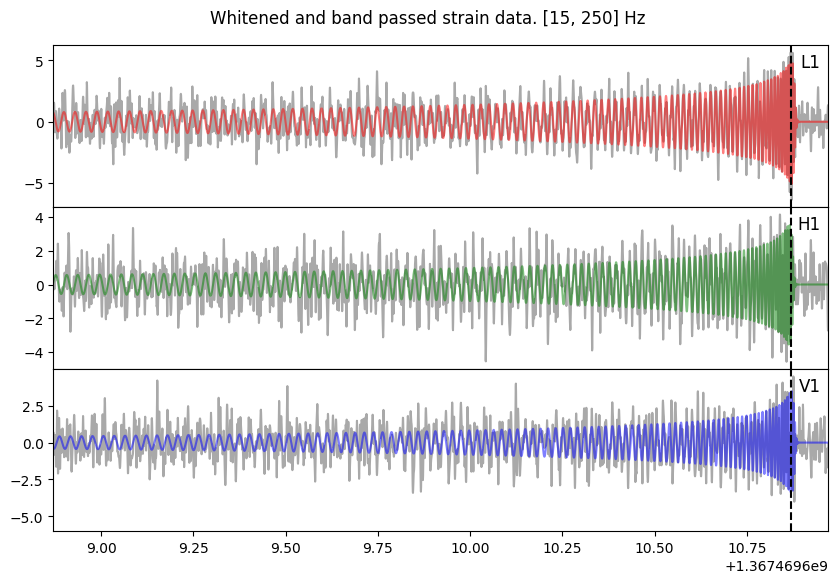

In [163]:
# Plotting whitened and BP data and signal in all the detectors.
fig, ax = plt.subplots(len(ifos), 1, sharex = True, figsize = (10, 6))
fig.subplots_adjust(hspace = 0)

fig.suptitle(f'Whitened and band passed strain data. {fband} Hz')
fig.subplots_adjust(top=0.92)

c = ['r', 'g', 'b']

for i, ifo in enumerate(ifos):
    ax[i].plot(data_whitenbp[ifo].sample_times, data_whitenbp[ifo], c = 'darkgray')
    ax[i].plot(signal_whitenbp[ifo].sample_times, signal_whitenbp[ifo], c = c[i], alpha = 0.5)
    ax[i].axvline(x = tTrigger, c = 'k', ls = '--')

    ax[i].set_title(ifo, x = 0.99, y = 0.95, pad = -10, fontsize = 12, loc='right')
    ax[i].set_xlim(tTrigger - 2, tTrigger + 0.1)

### Matched filtering SNR time series

Calculating matched-filter SNR in three detectors. Frequency band: [15, 250] Hz
Detector L1 : 42.4243
Detector H1 : 30.2083
Detector V1 : 24.1804


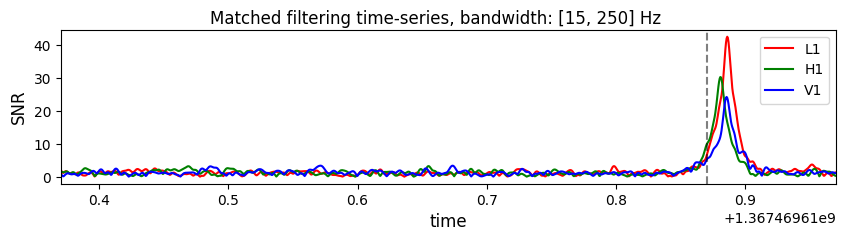

In [164]:
# Caculate matched-filter SNR in all the detectors.
print(f'Calculating matched-filter SNR in three detectors. Frequency band: {fband} Hz')

# To calculate the matched filter we need a template waveform, let us generate a template using `get_fd_waveform`.
hp, hc = get_fd_waveform(**frozenParams)
hp.resize(Nf)
matchedFilterSNR = {}
for detector in ifos:

    matchedFilterSNR[detector] = abs(matched_filter(template = hp, data = data_fd[detector], \
                                                psd=psd[detector], \
                                                low_frequency_cutoff = fband[0], high_frequency_cutoff = fband[1]))
    print('Detector %s : %0.4f'%(detector, abs(matchedFilterSNR[detector]).max()))

# Plotting the SNR time series.
fig, ax = plt.subplots(figsize = (10, 2))
fig.suptitle(f'Matched filtering time-series, bandwidth: {fband} Hz')
fig.subplots_adjust(top=0.88)

ax.set_prop_cycle(color=['red', 'green', 'blue', 'magenta'])

for i, ifo in enumerate(ifos):
    ax.plot(matchedFilterSNR[ifo].sample_times, matchedFilterSNR[ifo], label = ifo)

ax.axvline(x = tTrigger, c = 'k', ls = '--', alpha=0.5)
ax.set_xlabel('time', fontsize = 12)
ax.set_ylabel('SNR', fontsize = 12)
ax.set_xlim(tTrigger - 0.5, tTrigger + 0.1)
plt.legend()

plt.show()

### Plot the cross correlation vs time-lag

Trigger GPS time: 1367469610.8703537 s
Calculating cross-corr using [-3.5, 1.5] s of data around reference GPS time 1367469610.8703537
Reference time is 0.0 s away from the trigger time
Processing pair: L1-H1
Noisy: Lagxy shape (20479,), Corrxy shape (20479,)
Signal: Lagxy shape (20479,), Corrxy shape (20479,)
Processing pair: L1-V1
Noisy: Lagxy shape (20479,), Corrxy shape (20479,)
Signal: Lagxy shape (20479,), Corrxy shape (20479,)
Processing pair: H1-V1
Noisy: Lagxy shape (20479,), Corrxy shape (20479,)
Signal: Lagxy shape (20479,), Corrxy shape (20479,)


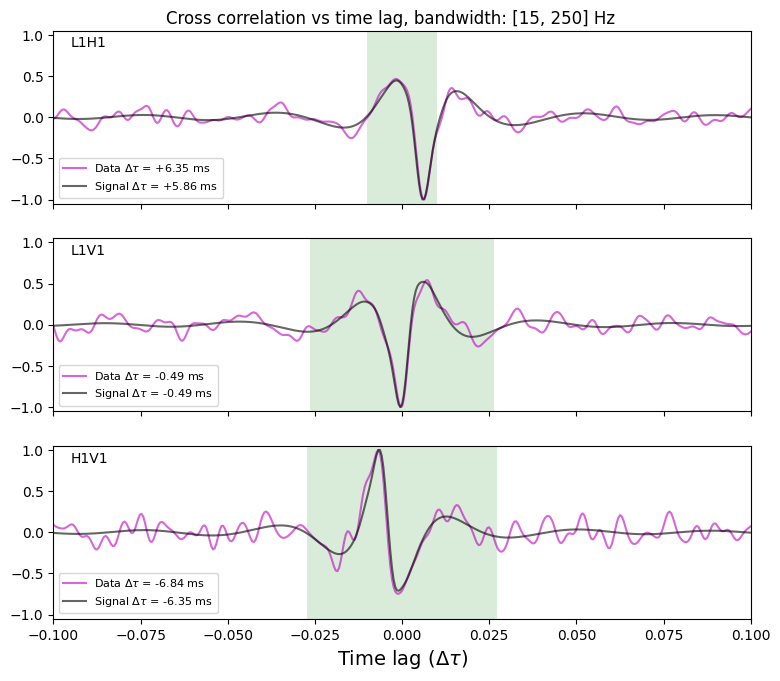

In [165]:
fig, ax = plt.subplots(len(ifos), 1, sharex = True, figsize = (9, 7))

fig.suptitle(f'Cross correlation vs time lag, bandwidth: {fband} Hz')
fig.subplots_adjust(top=0.95)


light_time = {'L1H1':0.010012846152267725, 'L1V1':0.02644834101635671, 'H1V1':0.027287979933397113}
tInterval = [-3.5, 1.5]
tRef = tTrigger

print (f'Trigger GPS time: {tTrigger} s')
print (f'Calculating cross-corr using {tInterval} s of data around reference GPS time {tRef}')
print (f'Reference time is {tRef - tTrigger} s away from the trigger time')

# Set the default color cycle
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=["m", "k", "c"])
p = 0

for i, ifoA in enumerate(ifos):
    for j, ifoB in enumerate(ifos):

        if j>i:
            print(f"Processing pair: {ifoA}-{ifoB}")

            #--------- For noisy data
            lagxy, corrxy = calc_xcorr(data_whitenbp[ifoA], data_whitenbp[ifoB], tRef, tInterval, ifnormalize=True)
            print(f"Noisy: Lagxy shape {lagxy.shape}, Corrxy shape {corrxy.shape}")
            #-- calculate the time-lag between the signals
            lt_AB = light_time[f'{ifoA}{ifoB}'] #-- look up the light travel time

            k = np.where(np.abs(lagxy) <= lt_AB)
            idx = np.abs(corrxy[k]).argmax() + k[0][0]
            lag = lagxy[idx]

            ax[p].axvspan(-lt_AB, lt_AB, facecolor='g', alpha=0.15)
            ax[p].plot(lagxy, corrxy, label=rf'Data $\Delta\tau$ = {lag*1000:+.2f} ms', alpha=0.6)

            #---------- For pure signals (no noise)
            lagxy, corrxy = calc_xcorr(signal_whitenbp[ifoA], signal_whitenbp[ifoB], tRef, tInterval, ifnormalize=True)
            print(f"Signal: Lagxy shape {lagxy.shape}, Corrxy shape {corrxy.shape}")

            #-- calculate the time-lag between the signals
            k = np.where(np.abs(lagxy) <= lt_AB) # light-travel time only
            idx = np.abs(corrxy[k]).argmax() + k[0][0]
            lag = lagxy[idx]

            ax[p].plot(lagxy, corrxy, label=rf'Signal $\Delta\tau$ = {lag*1000:+.2f} ms', alpha=0.6)

            ax[p].text(-.095, 0.85, f'{ifoA}{ifoB}')
            ax[p].set_xlim(-.10, 0.10)
            ax[p].set_ylim(-1.05, 1.05)
            ax[p].legend(fontsize=8, loc=3)

            plt.xlabel(r'Time lag ($\Delta\tau$)', fontsize=14)

            p += 1           

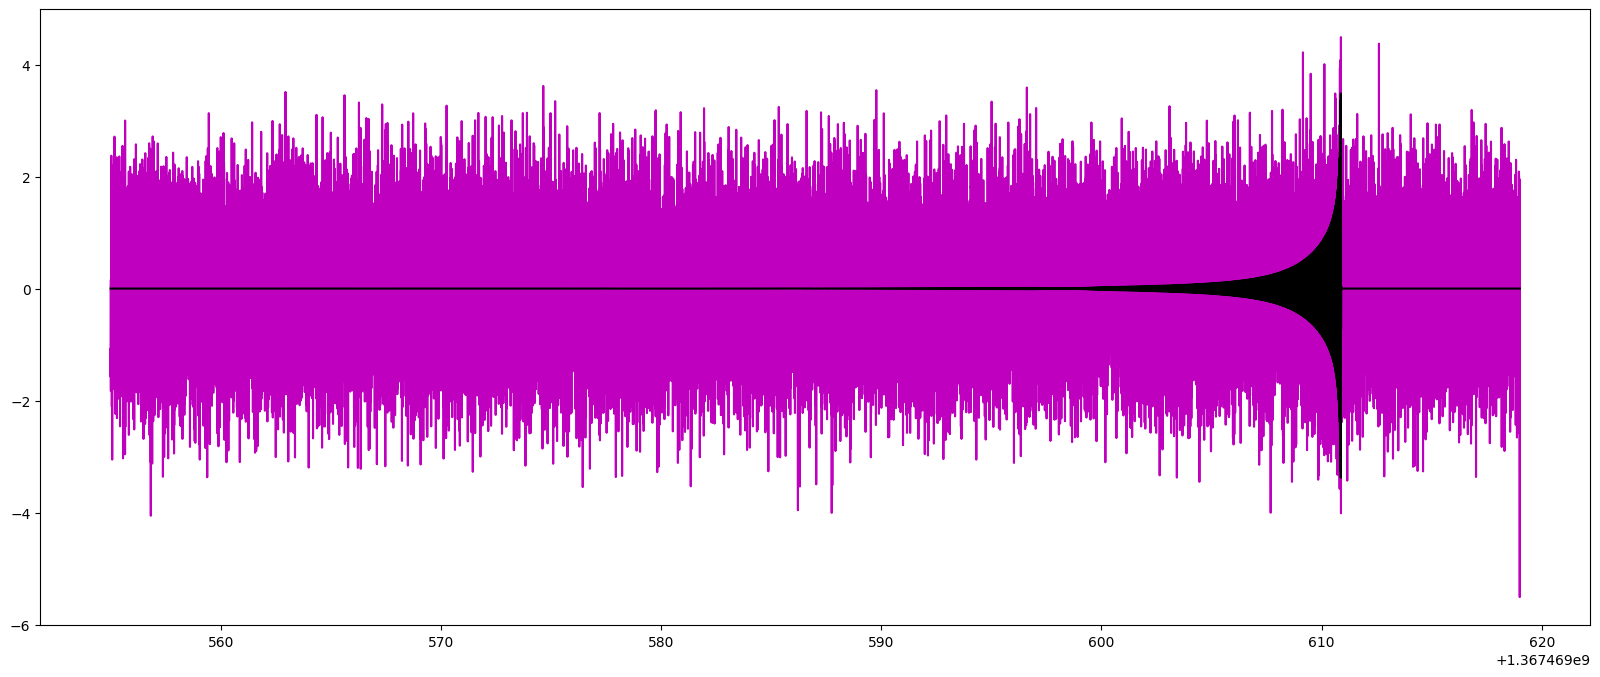

In [166]:
plt.figure(figsize = (20 , 8))
plt.plot(data_whitenbp['V1'].sample_times , data_whitenbp['V1'])
plt.plot(signal_whitenbp['V1'].sample_times , signal_whitenbp['V1'] , c = 'black')
plt.show()

### Slicing the signal with white noise with 10 seconds before the merger and 0.1 sec after the merger

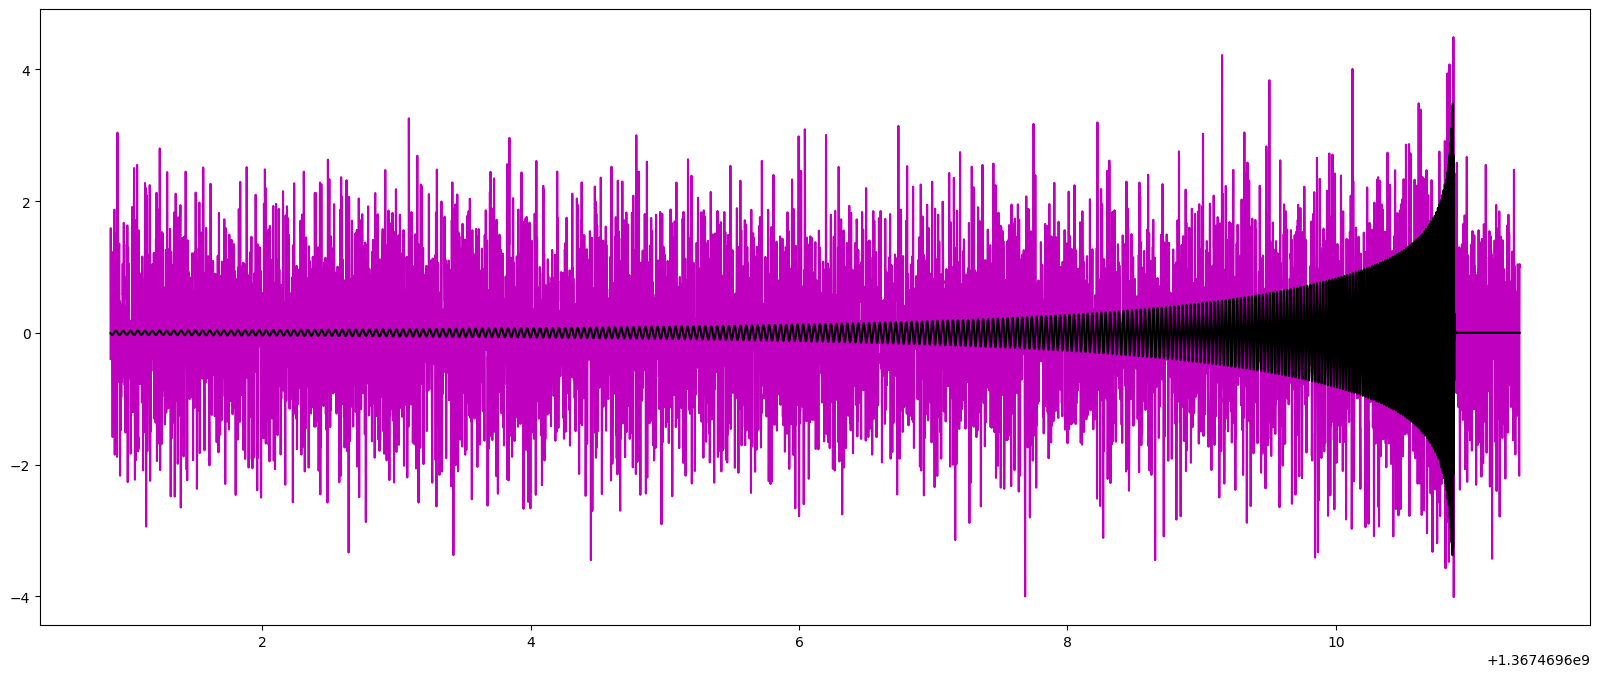

In [167]:
W = data_whitenbp['V1'].time_slice(tTrigger -10 , tTrigger +0.5)
O_S = signal_whitenbp['V1'].time_slice(tTrigger -10 , tTrigger +0.5) 
plt.figure(figsize = (20 , 8))

plt.plot(W.sample_times , W)
plt.plot(O_S.sample_times, O_S)

The **analytic signal** \( z(t) \) is defined as:

$$
z(t) = x(t) + j \, H[x](t)
$$

where \( H[x](t) \) is the Hilbert transform of \( x(t) \), and \( j \) is the imaginary unit.

The **instantaneous amplitude** \( A(t) \) is given by:

$$
A(t) = \sqrt{x(t)^2 + H[x](t)^2}
$$

The **instantaneous phase** \( \theta(t) \) is:

$$
\theta(t) = \arctan\left(\frac{H[x](t)}{x(t)}\right)
$$


# Normal hilbert transform from Scipy

The **analytic signal** \( z(t) \) is defined as:

$$
z(t) = x(t) + j \, H[x](t)
$$

where \( H[x](t) \) is the Hilbert transform of \( x(t) \), and \( j \) is the imaginary unit.

The **instantaneous amplitude** \( A(t) \) is given by:

$$
A(t) = \sqrt{x(t)^2 + H[x](t)^2}
$$

The **instantaneous phase** \( \theta(t) \) is:

$$
\theta(t) = \arctan\left(\frac{H[x](t)}{x(t)}\right)
$$


The **instantaneous phase** \( IF\) is:

$$
f(t) = \frac{1}{2\pi} \frac{d\theta(t)}{dt}
$$


In [168]:
from scipy.signal import hilbert, chirp
analytical_signal = hilbert(W)
aplitude_envelope = np.abs(analytical_signal)
IP = np.unwrap(np.angle(analytical_signal))
IF = (np.diff(IP)/(2.0*np.pi) *fsamp)
t =  W.sample_times

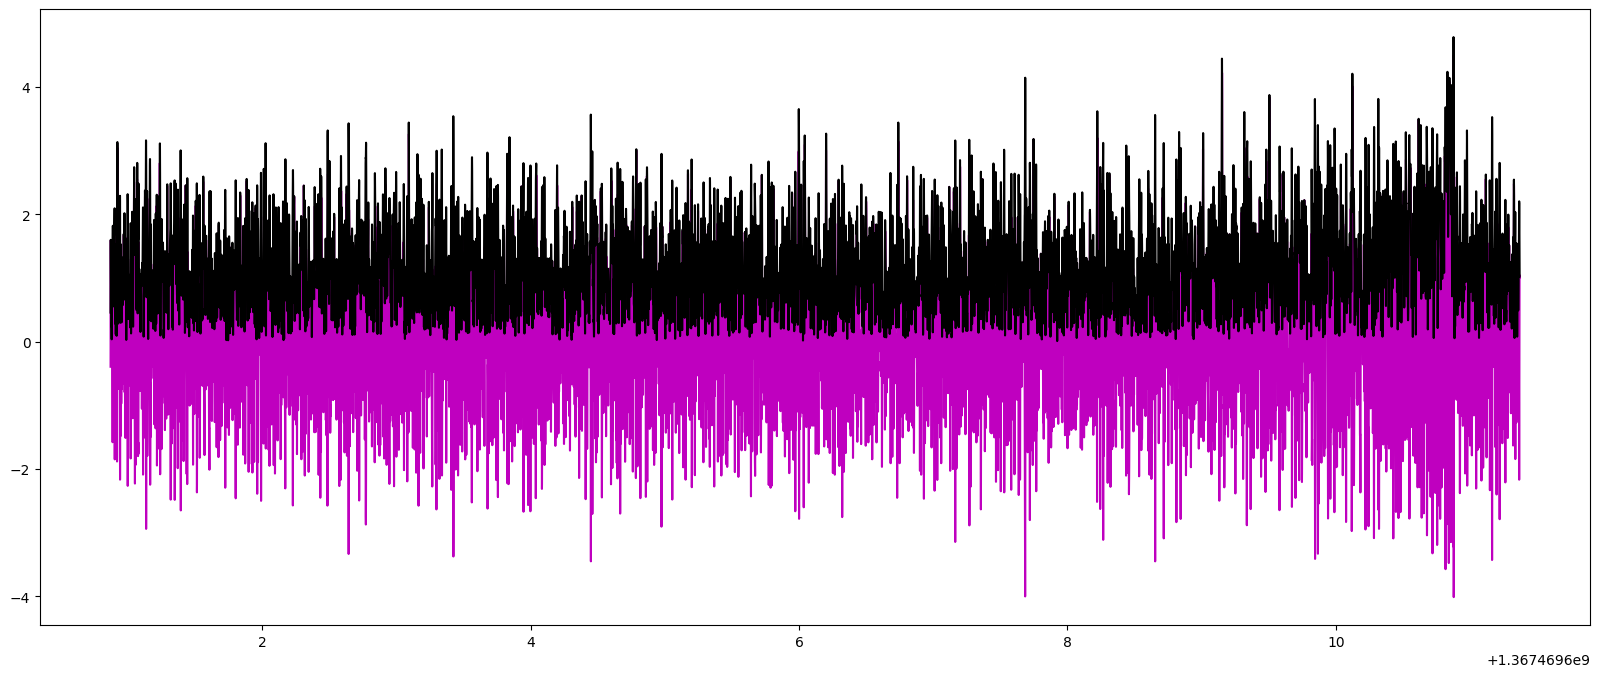

In [169]:
plt.figure(figsize=(20,8))
plt.plot(t, W)
plt.plot(t, aplitude_envelope)

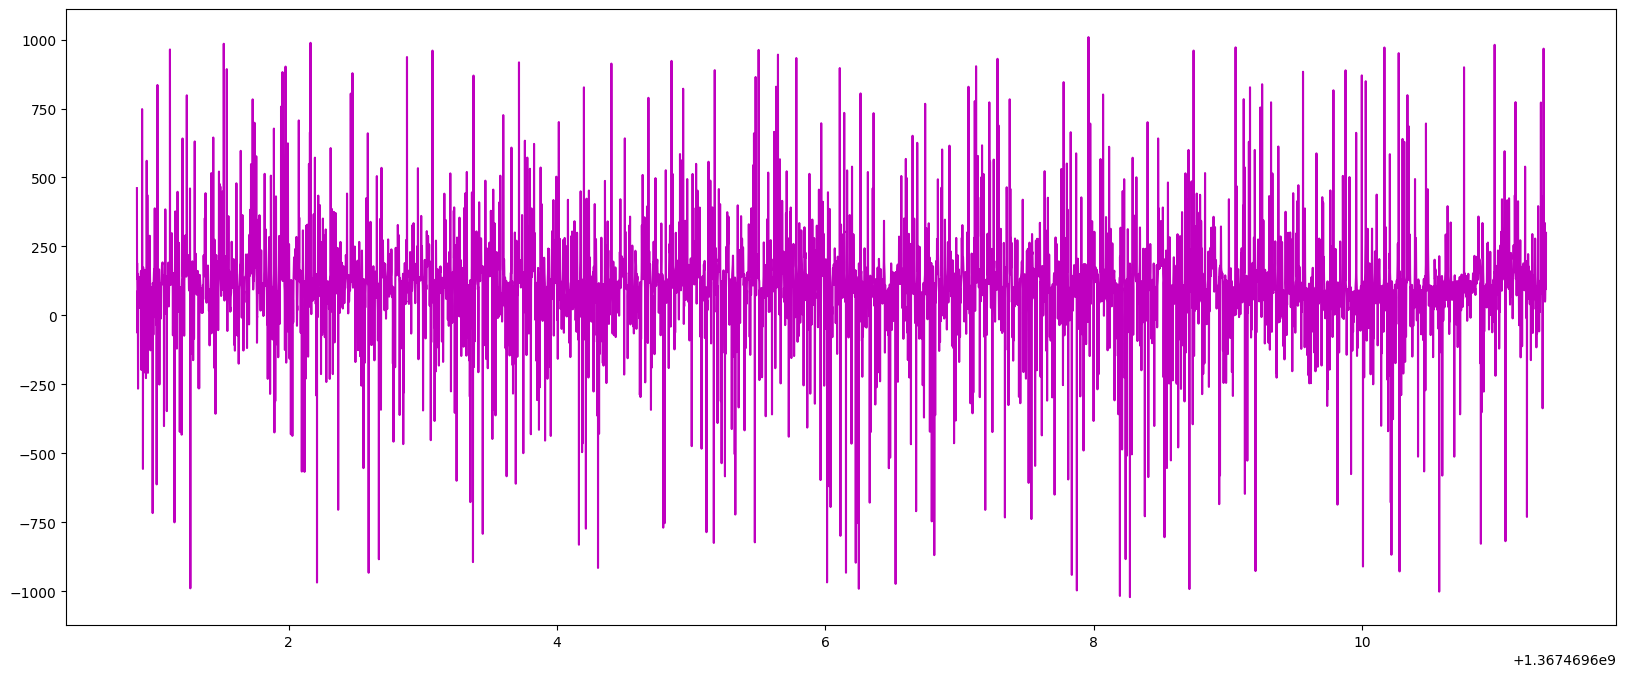

In [170]:
plt.figure(figsize=(20,8))
plt.plot(t[1:], IF)

### EMD (Emperical mode decomposition)
- breaks the signal into subsequent imf without leaving the time domain
- emd satisfies the perfect reconstruction property superimposing all extracted IMFs together with the residuals reconstruct the original signal

### Empirical Mode Decomposition (EMD) Algorithm

The EMD algorithm decomposes a signal \( x(t) \) into a sum of **Intrinsic Mode Functions (IMFs)** and a residual term \( r(t) \):

$$
x(t) = \sum_{i=1}^{n} \text{IMF}_i(t) + r(t)
$$

Where:
- IMFi(t) represents the i-th Intrinsic Mode Function.
- r(t) is the residual signal after decomposition.

#### Initial Setup:
For the first decomposition:
- $$ Set ( r_{0}(t) = x(t) ) $$

#### Step 1: Initialize the Process
1. Set $$( h_0(t) = r_{n-1}(t) ) \ (the\ residual\ from\ the\ previous\ decomposition)$$.
2. Initialize k = 1.

#### Step 2: Identify Local Extrema
- Identify all **local maxima** and **local minima** of the signal $$ ( h_{k-1}(t) ) $$.

#### Step 3: Create Envelopes
- Create the **upper envelope** using cubic spline interpolation through the local maxima.
- Create the **lower envelope** using cubic spline interpolation through the local minima.

#### Step 4: Compute the Mean Envelope
- Calculate the **mean envelope** as the average of the upper and lower envelopes.

#### Step 5: Extract the Detail
- Subtract the mean envelope from the signal $$ text( h_{k-1}(t) ): $$
  $$ d_k(t) = h_{k-1}(t) - \text{mean envelope} $$

#### Step 6: Check IMF Criteria
- If the detail dk(t) satisfies the **IMF conditions** (number of zero-crossings equals the number of extrema or differs by at most one), then it is considered an IMF.
- If the IMF criteria are met, assign it as $$( \text{IMF}_k(t) ).$$

#### Step 7: Update the Residual
- Update the residual:
  $$ r_k(t) = h_{k-1}(t) - \text{IMF}_k(t) $$

#### Step 8: Repeat
- Repeat the process until the residual $$( r_k(t) )$$ becomes monotonic, meaning no more oscillations are present that can be decomposed into an IMF.



### Hilbert transform on IMFs

$$
H[\text{IMF}_i](t) = \frac{1}{\pi} \, \text{P.V.} \int_{-\infty}^{\infty} \frac{\text{IMF}_i(\tau)}{t - \tau} \, d\tau
$$

- Analytical signal

$$
z_i(t) = \text{IMF}_i(t) + j H[\text{IMF}_i](t) = A_i(t) e^{j \theta_i(t)}
$$

- IA

$$
A_i(t) = \sqrt{\text{IMF}_i(t)^2 + H[\text{IMF}_i](t)^2}
$$

- IP

$$
\theta_i(t) = \arctan \left( \frac{\text{IMF}_i(t)}{H[\text{IMF}_i](t)} \right)
$$

- IF

$$
f_i(t) = \frac{1}{2 \pi} \frac{d\theta_i(t)}{dt}
$$

In [171]:
import emd
def frequencytransform(fs, method):
    imf = emd.sift.sift(W)
    IP, IF, IA = emd.spectra.frequency_transform(imf, fs, method)
    freq_range = (0, 1000, 100)
    t = W.sample_times
    f, hht = emd.spectra.hilberthuang(IF, IA,freq_range, sum_time= False)
    return IP, IF, IA, imf,f,hht

In [172]:
method = 'nht'
IP, IF, IA, imf,f,hht = frequencytransform(fsamp, method)
m,n = imf.shape

<Axes: xlabel='Time (samples)'>

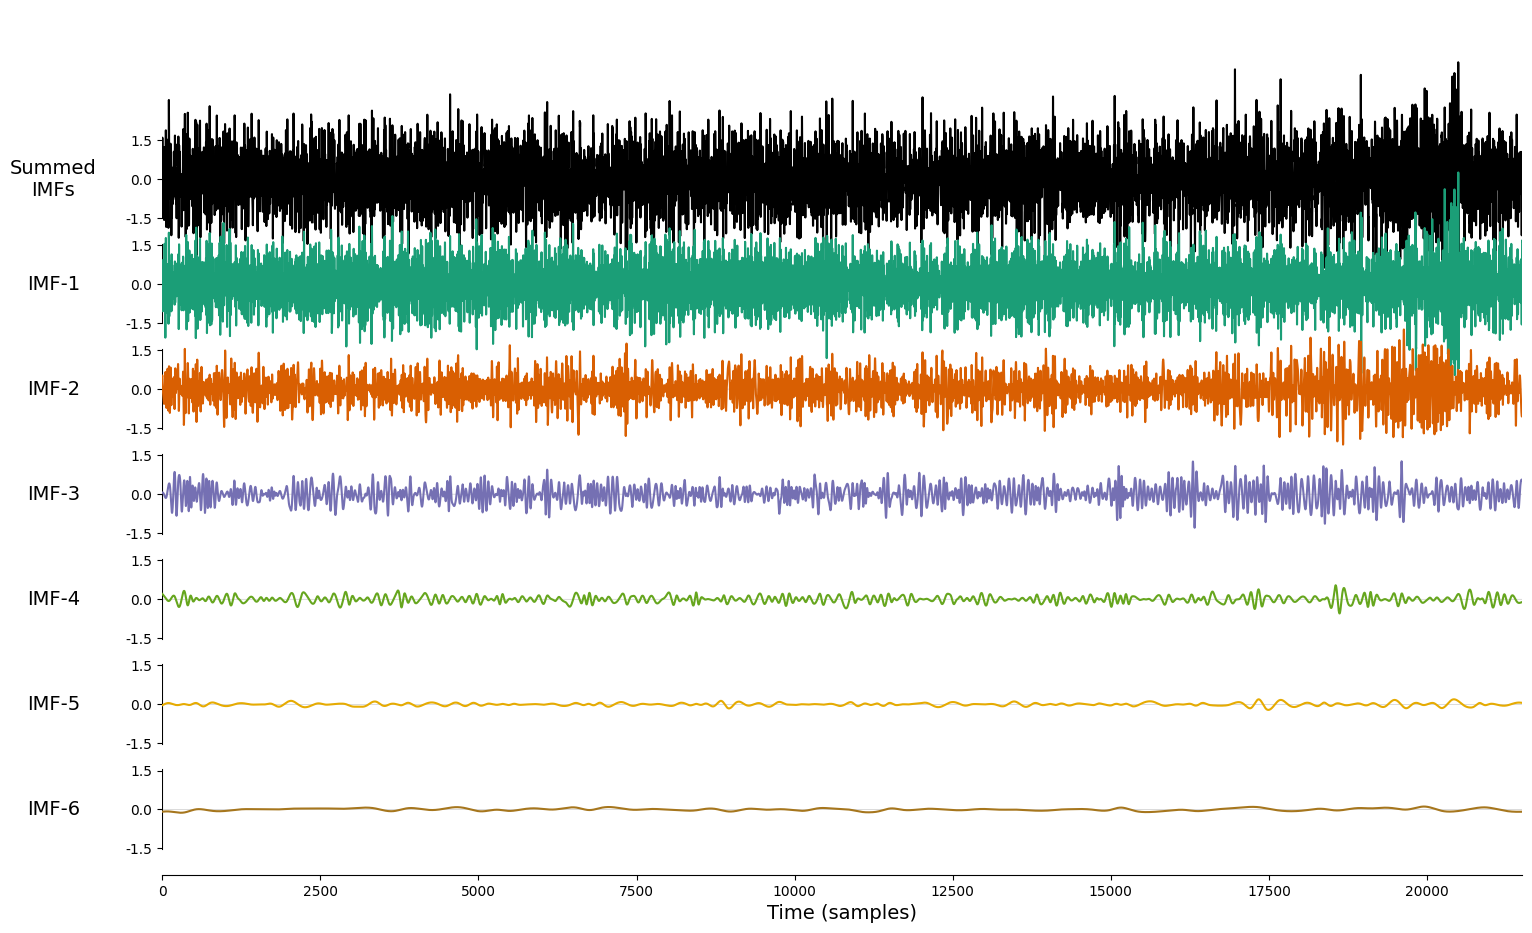

In [173]:
emd.plotting.plot_imfs(imf)

- If we represent each IMF’s amplitude in a 2D matrix with frequency on the y-axis and time on the x-axis, we can create a spectrogram-like matrix. 
- This matrix \( H(t,f) \) (often called the Hilbert-Huang Spectrum \( HHS(t,f) \)) shows how the amplitude of the signal varies with both time and frequency.

$$
HHS(t,f) = \sum_{i=1}^{n} A_i(t) \delta(f - f_i(t))
$$

<Axes: title={'center': 'Hilbert-Huang Transform'}, xlabel='Time', ylabel='Frequency'>

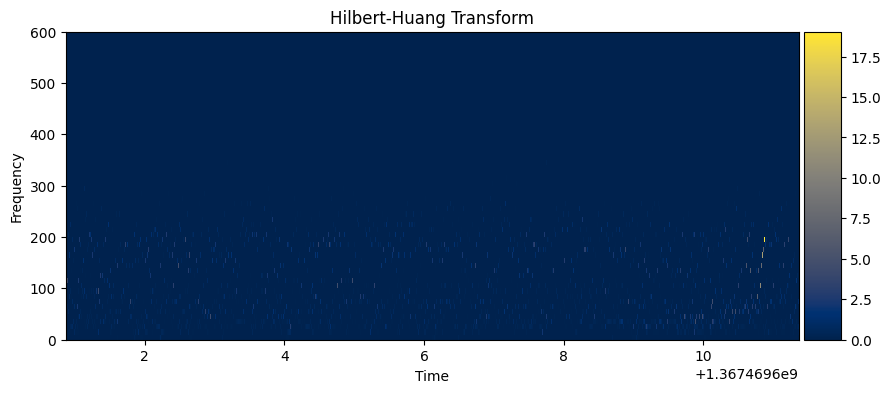

In [175]:
fig = plt.figure(figsize=(10, 4))
emd.plotting.plot_hilberthuang(hht, t, f, freq_lims=(0, 600), fig=fig, cmap= 'cividis')

## Plotting spectrum

In [176]:
freq_edges, freq_centres = emd.spectra.define_hist_bins(0, 500, 500, 'linear')
# print(freq_edges)
f, spec_unweighted = emd.spectra.hilberthuang(IF, np.ones_like(IA), freq_edges, sum_imfs=False)

In [177]:
f, spec_weighted = emd.spectra.hilberthuang(IF, IA, freq_edges, sum_imfs=False)

Text(0, 0.5, 'IF')

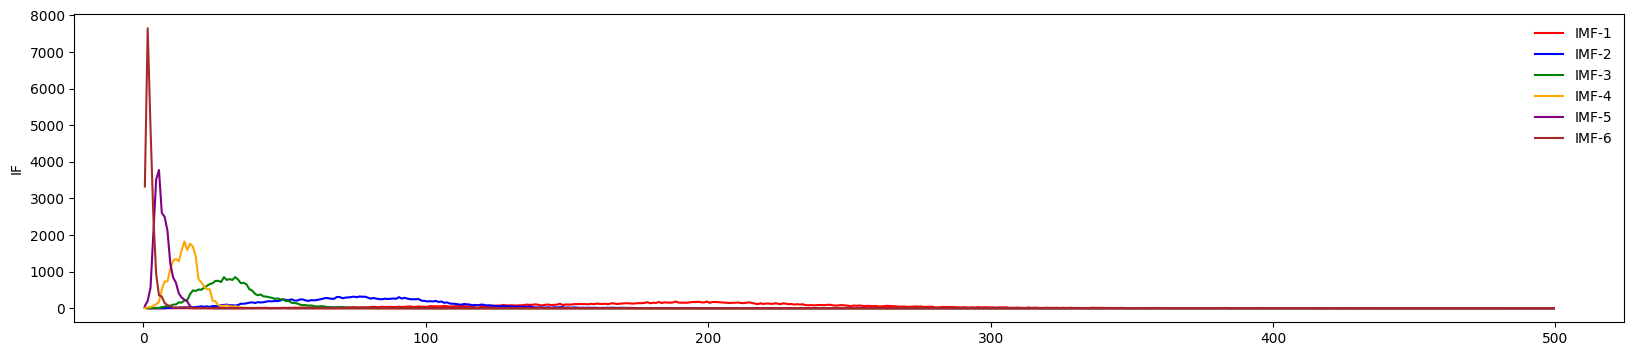

In [178]:
# Example: Assuming `spec_unweighted` has 6 columns (one for each IMF)
plt.figure(figsize=(20, 4))

# Define custom colors for each IMF
colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']

# Plot each IMF spectrum
for i in range(n):  # Adjust range if the number of IMFs differs
    plt.plot(freq_centres, spec_unweighted[:, i], color=colors[i], label=f'IMF-{i+1}')

# Add legend
plt.legend(frameon=False)
plt.ylabel("IF")

Text(0, 0.5, 'IF')

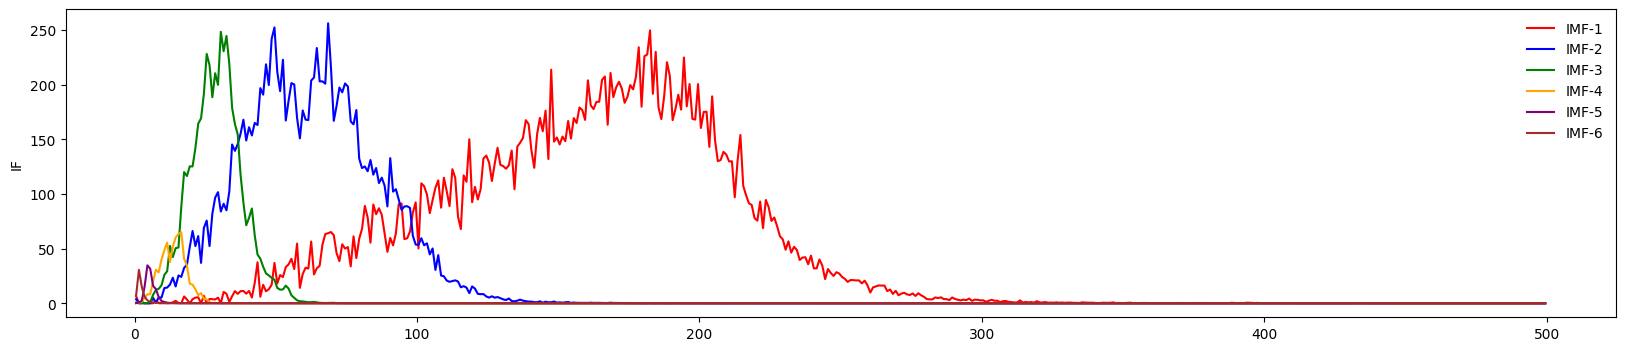

In [179]:
# Example: Assuming `spec_unweighted` has 6 columns (one for each IMF)
plt.figure(figsize=(20, 4))

# Define custom colors for each IMF
colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']

# Plot each IMF spectrum
for i in range(n):  # Adjust range if the number of IMFs differs
    plt.plot(freq_centres, spec_weighted[:, i], color=colors[i], label=f'IMF-{i+1}')

# Add legend
plt.legend(frameon=False)
plt.ylabel("IF")

Text(0, 0.5, 'IF')

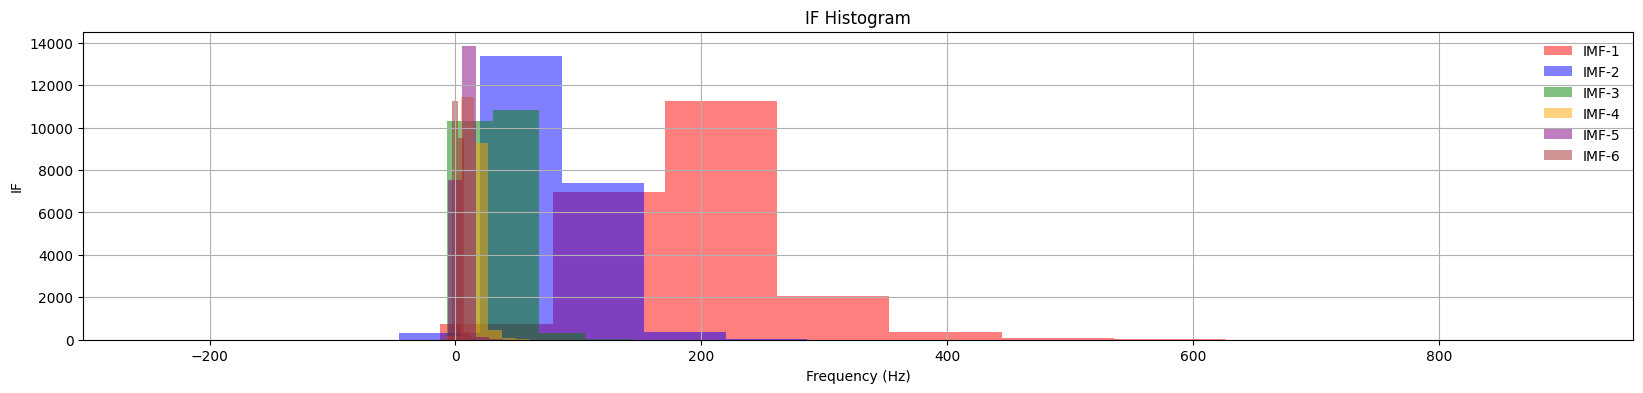

In [180]:
plt.figure(figsize=(20, 4))

colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']  # Define unique colors

# Plot histogram for each IMF
for i in range(n):
    plt.hist(IF[:, i], color=colors[i], alpha=0.5, label=f'IMF-{i+1}') 

# Add grid, title, labels, and legend
plt.grid(True)
plt.title('IF Histogram')
plt.xlabel('Frequency (Hz)')
plt.legend(frameon=False)
plt.ylabel("IF")

Text(0, 0.5, 'IF')

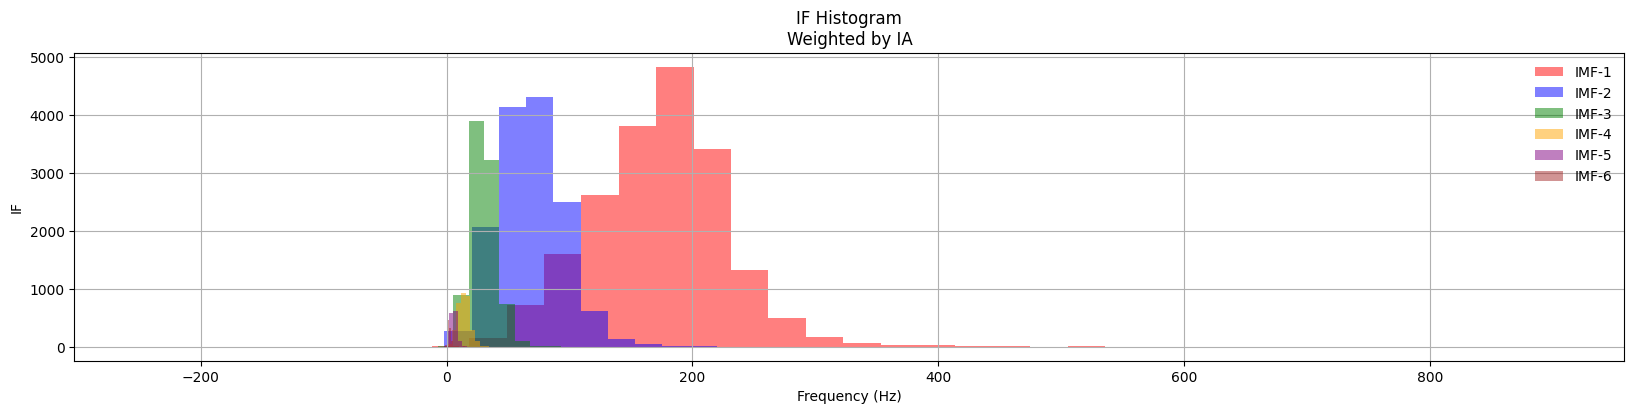

In [181]:
plt.figure(figsize=(20, 4))

colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']  # Unique colors for IMFs

# Plot histogram for each IMF weighted by IA
for i in range(n):
    plt.hist(IF[:, i], bins=30, weights=IA[:, i], color=colors[i], alpha=0.5, label=f'IMF-{i+1}')  # Adjust bins as needed

# Add grid, title, labels, and legend
plt.grid(True)
plt.title('IF Histogram\nWeighted by IA')
plt.xlabel('Frequency (Hz)')
plt.legend(frameon=False)
plt.ylabel("IF")


### IMF

In [182]:
def frequencytransform(i, fs, method):
    imf = emd.sift.sift(W)
    imf_n = imf[:, i]
    IP, IF, IA = emd.spectra.frequency_transform(imf_n, fs, method)
    freq_range = (0, 1000, 50)
    t = W.sample_times
    f, hht = emd.spectra.hilberthuang(IF, IA, freq_range, sum_time= False)
    return IP, IF, IA, imf_n,f,hht

In [183]:
method = 'nht'
i = 0
IP, IF, IA, imf_n,f,hht = frequencytransform(i, fsamp, method)

PLOT FOR IMF1


<Axes: title={'center': 'Hilbert-Huang Transform'}, xlabel='Time', ylabel='Frequency'>

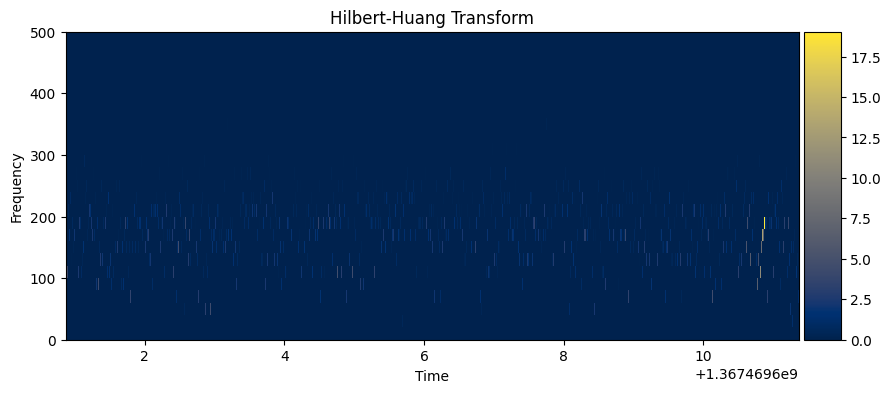

In [184]:
fig = plt.figure(figsize=(10, 4))
print(f"PLOT FOR IMF{i+1}")
emd.plotting.plot_hilberthuang(hht, t, f, freq_lims=(0, 500), fig=fig, cmap=  'cividis')

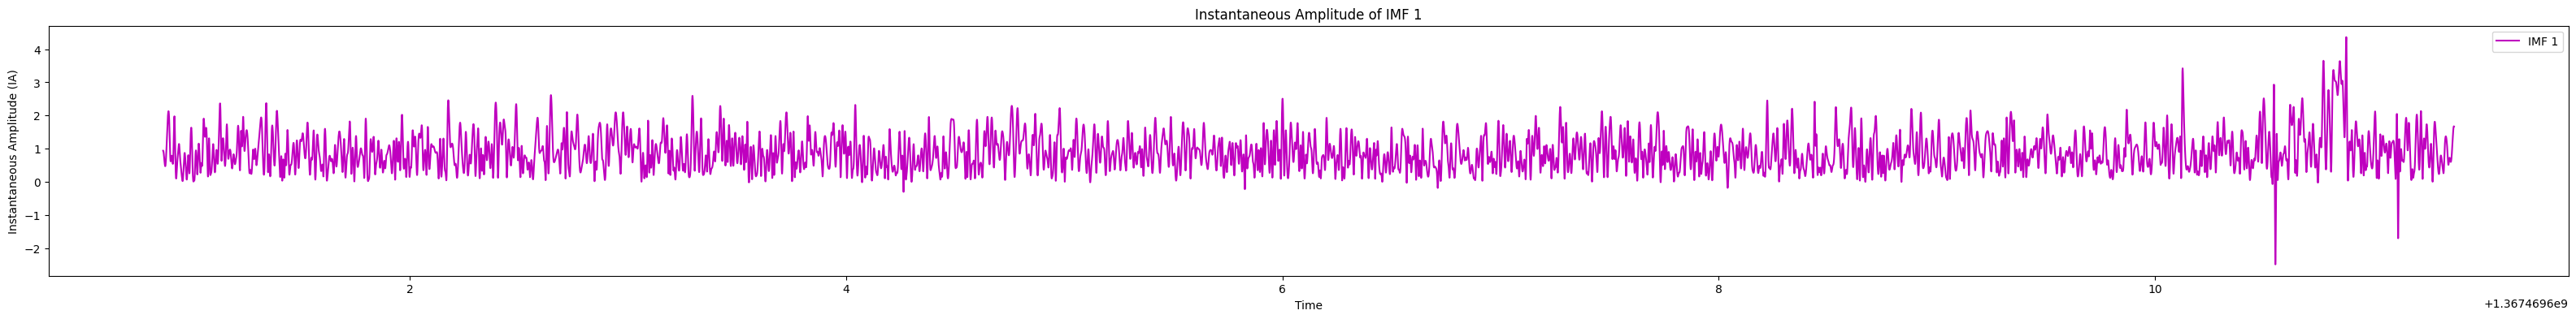

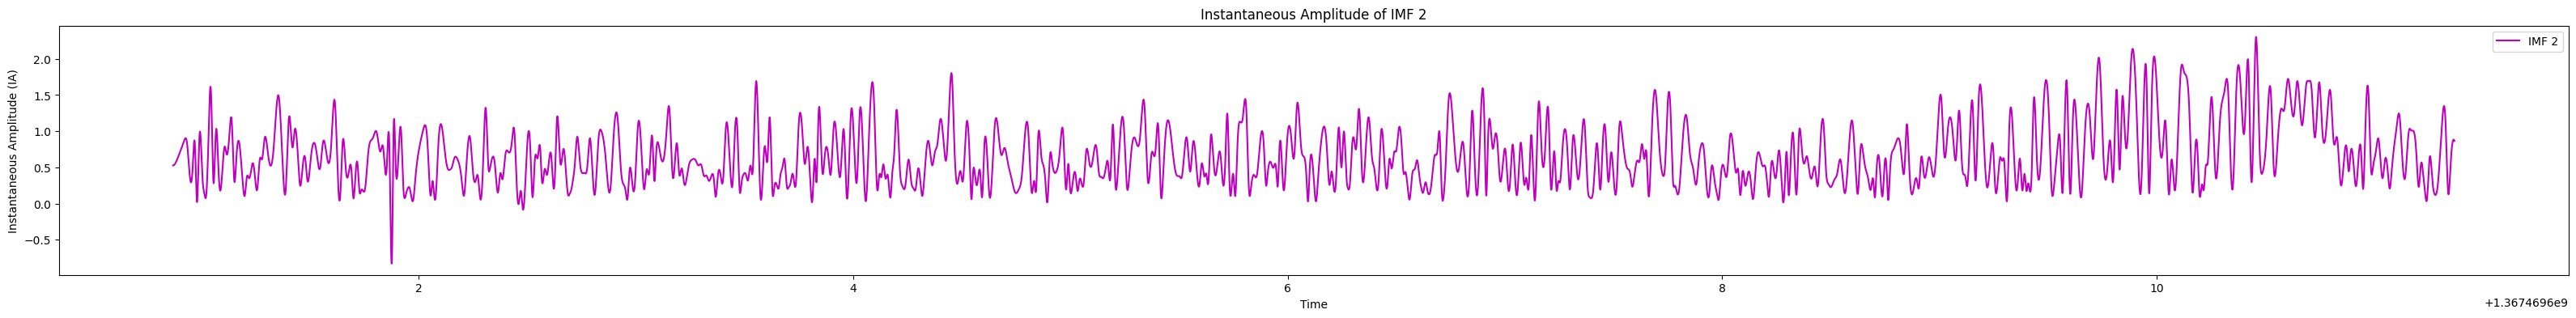

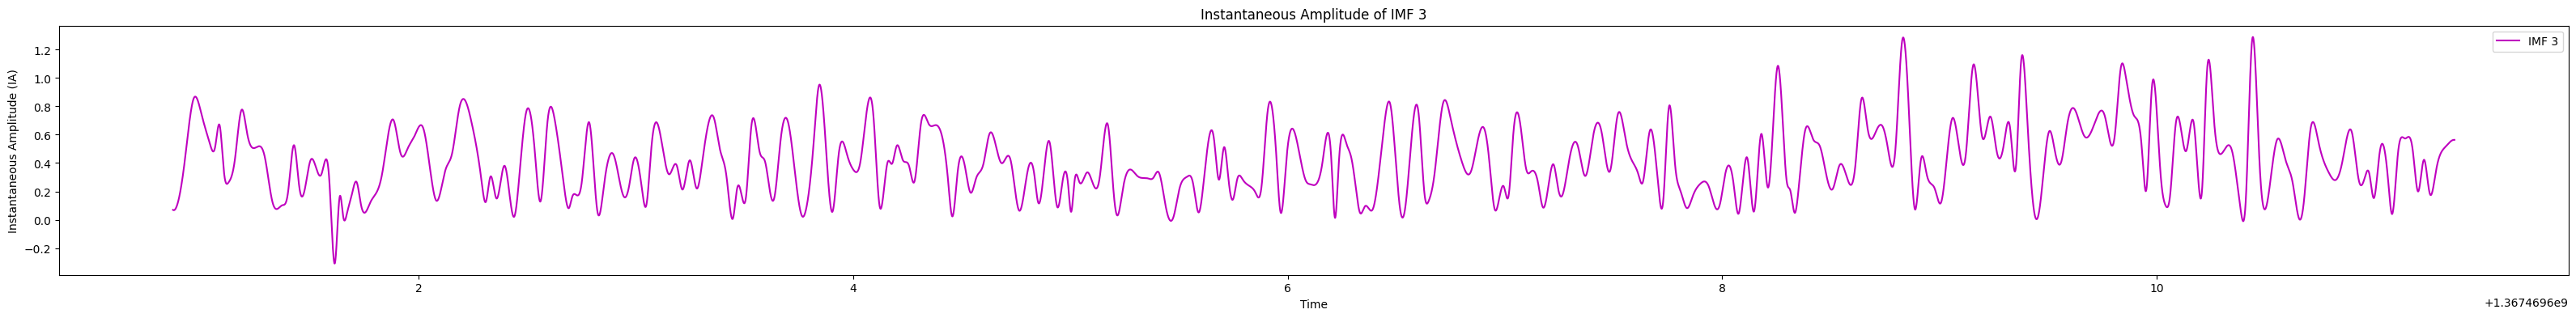

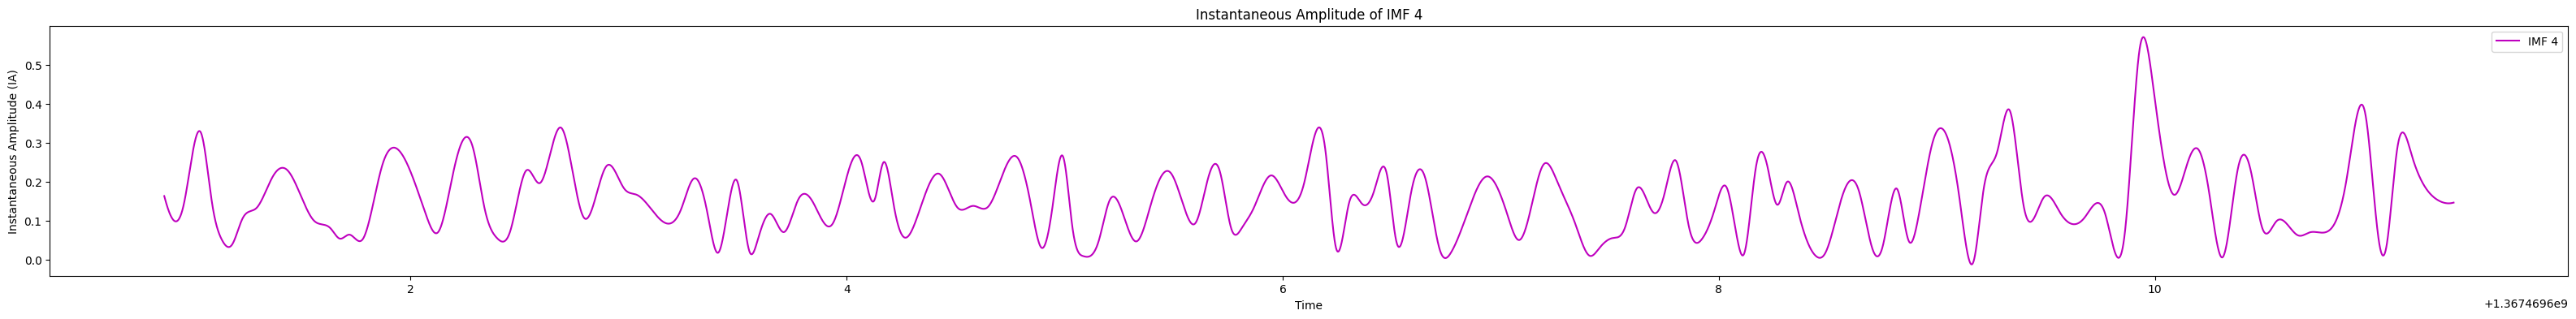

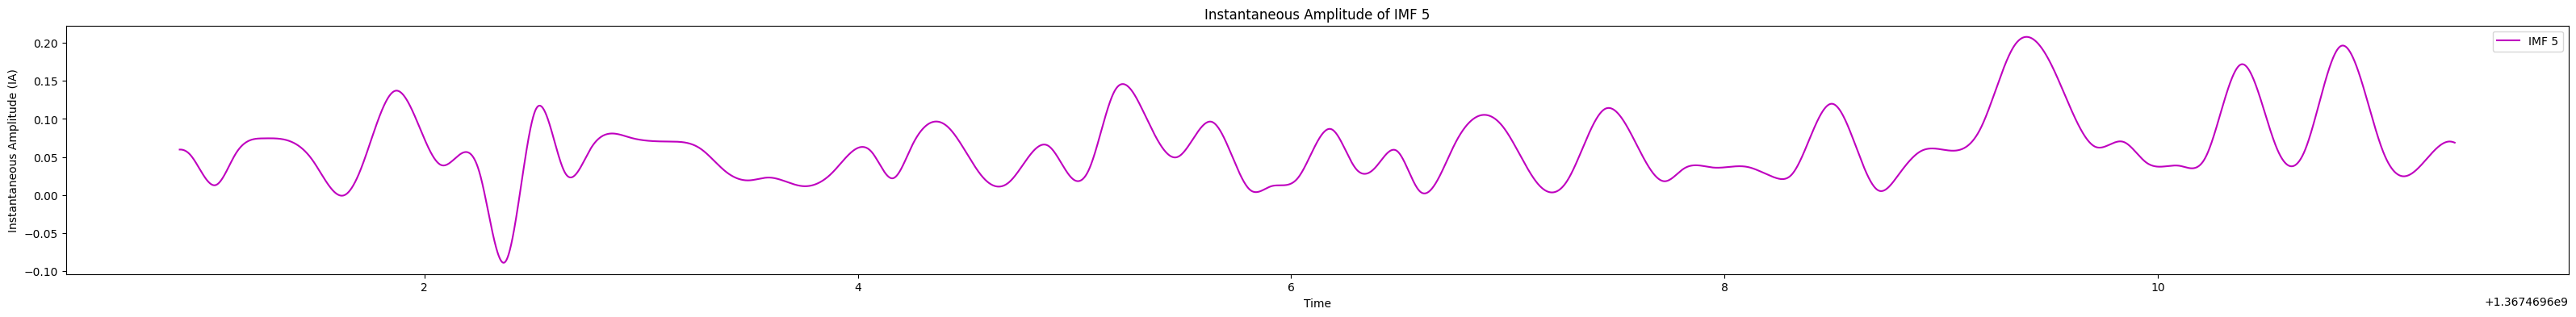

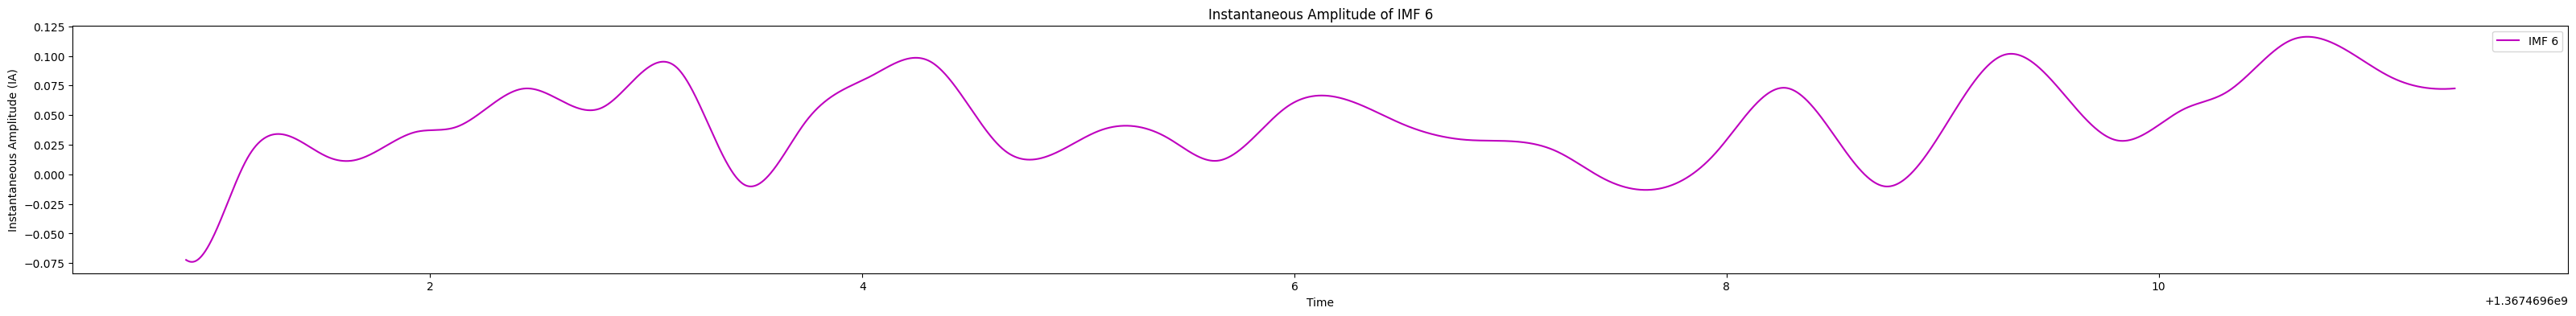

In [185]:
for i in range(n):
    # Run the function to obtain IA for the specific IMF component
    IP, IF, IA, imf_n, f, hht = frequencytransform(i, 7200, method)
    
    plt.figure(figsize=(40, 4))
    plt.plot(t, IA, label=f'IMF {i+1}')
    
    # Add labels, title, and legend
    plt.xlabel('Time')
    plt.ylabel('Instantaneous Amplitude (IA)')
    plt.title(f'Instantaneous Amplitude of IMF {i+1}')
    plt.legend()
    plt.show()

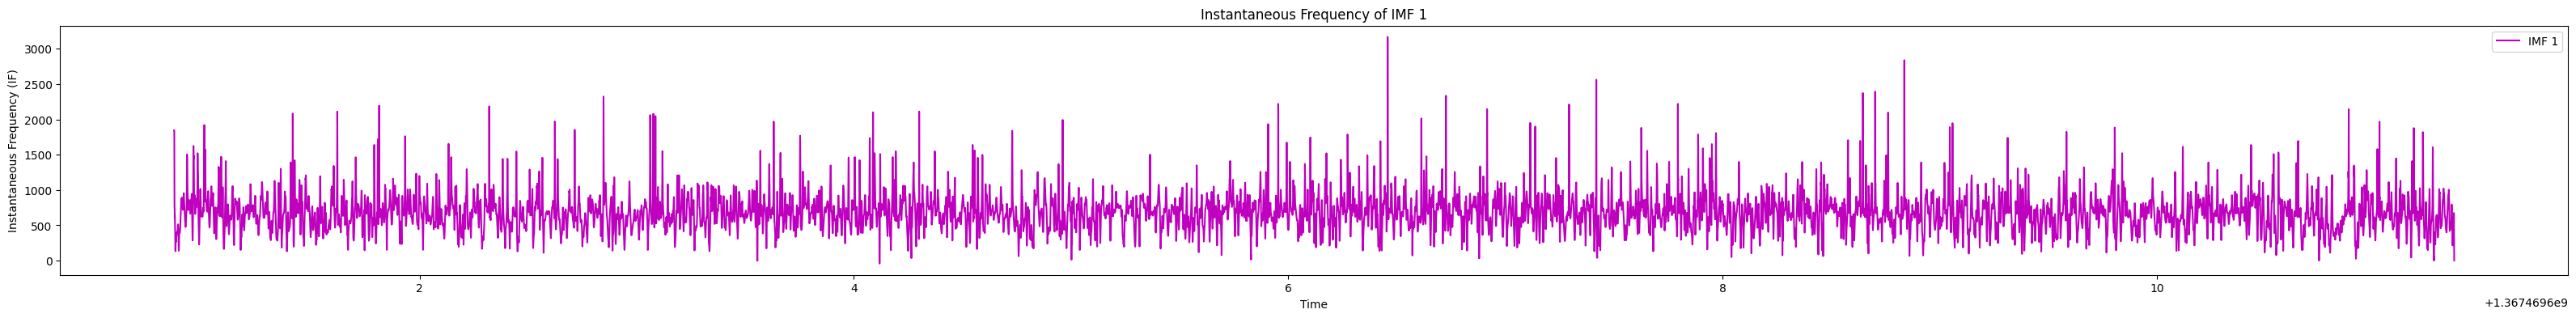

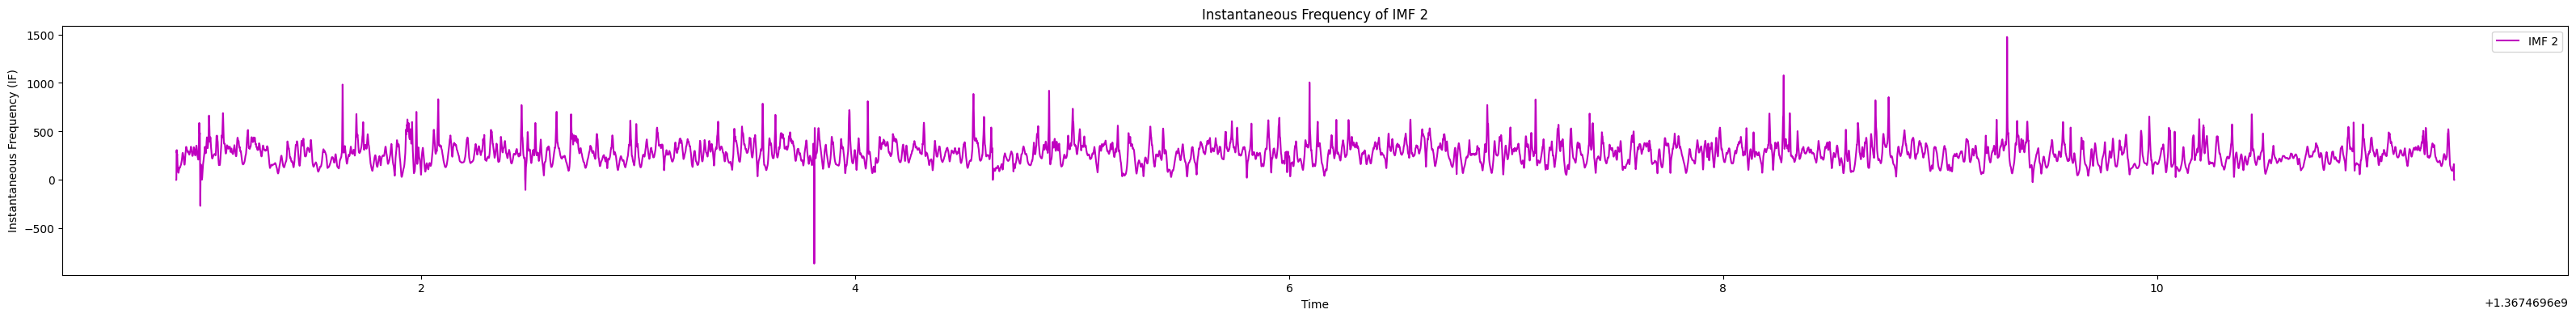

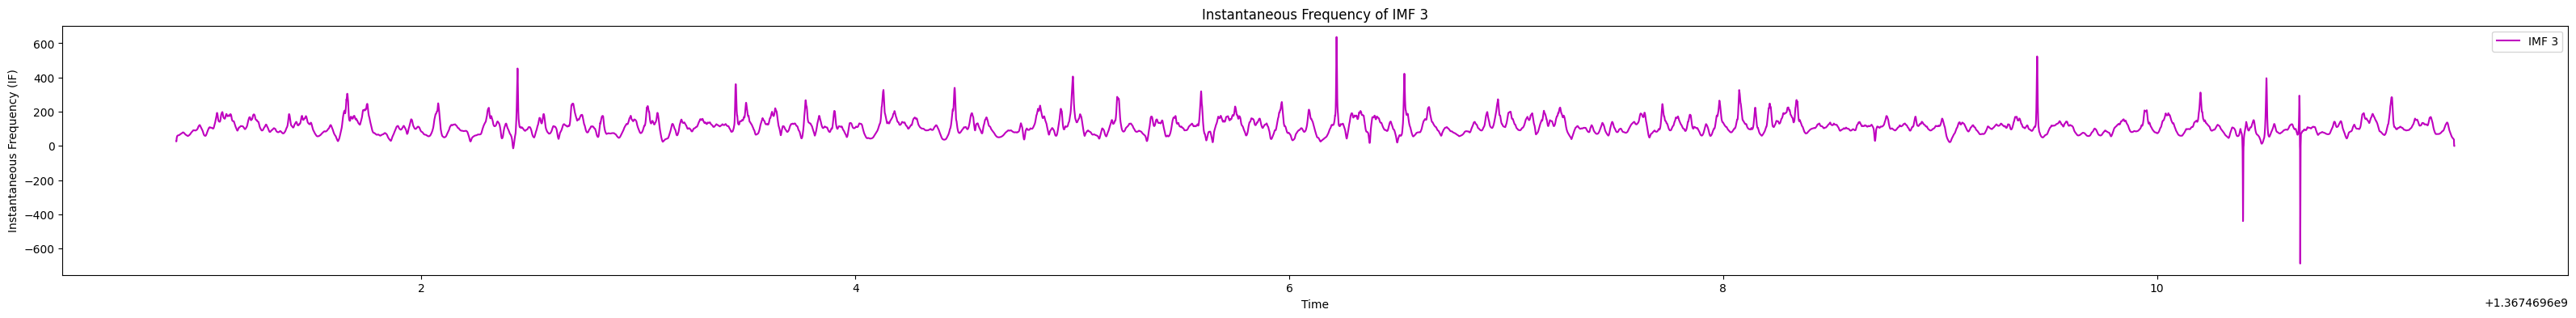

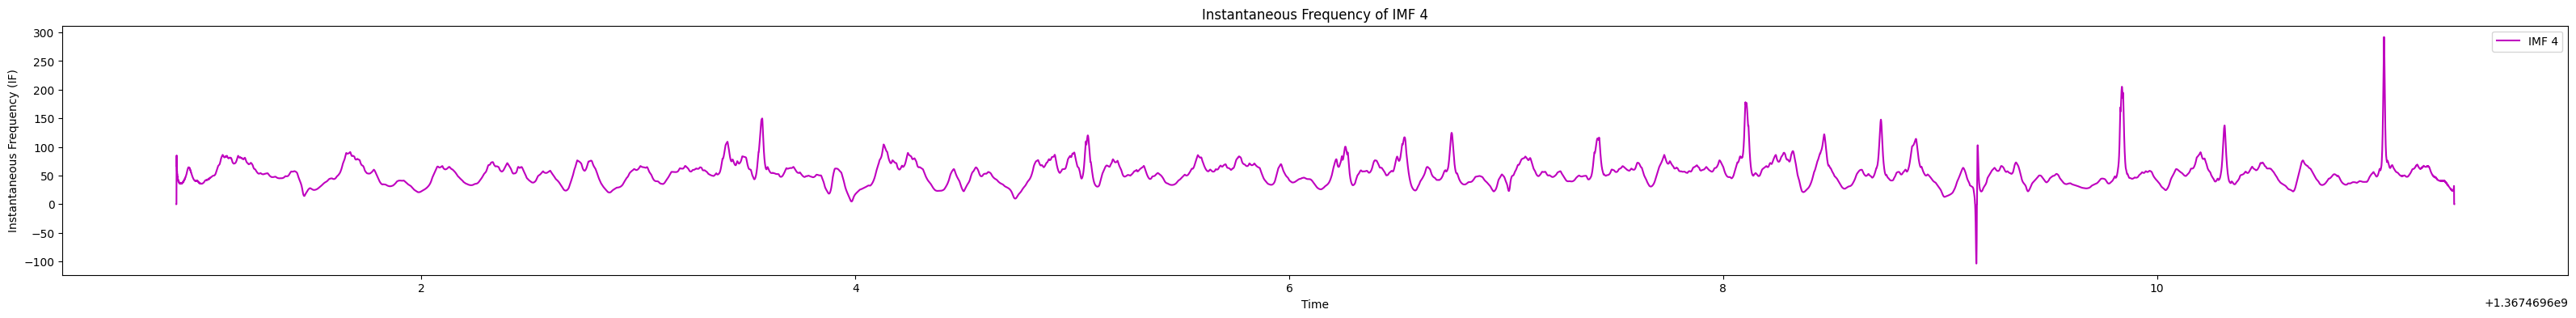

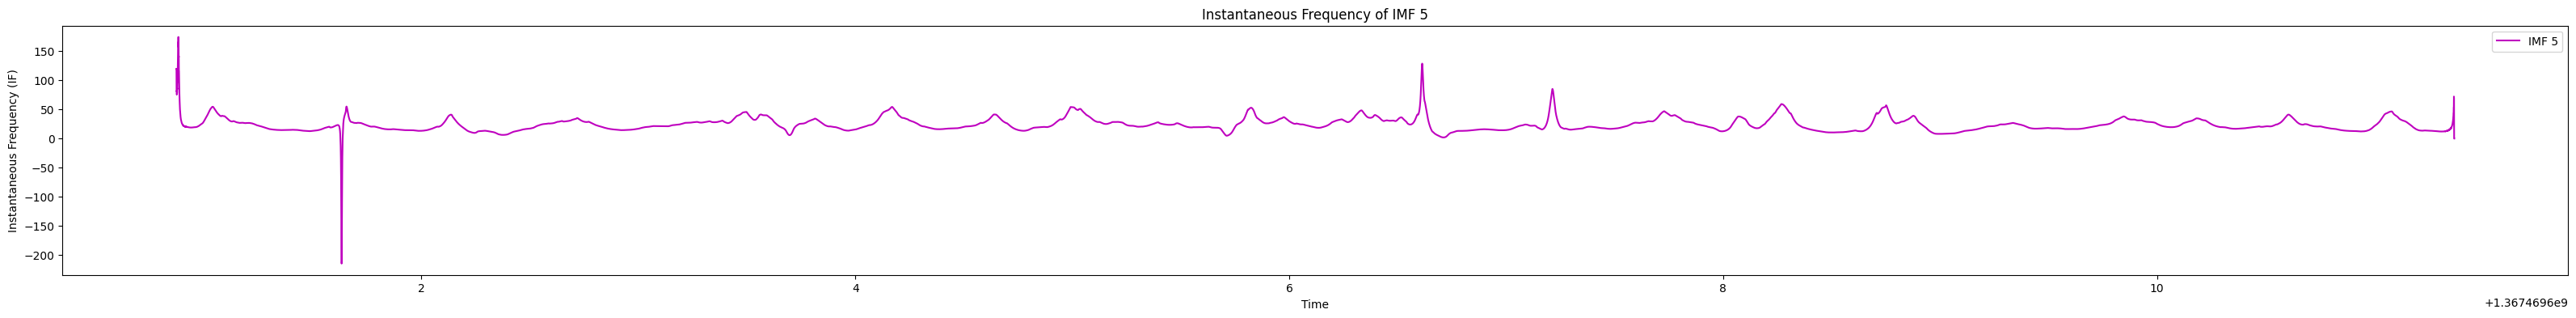

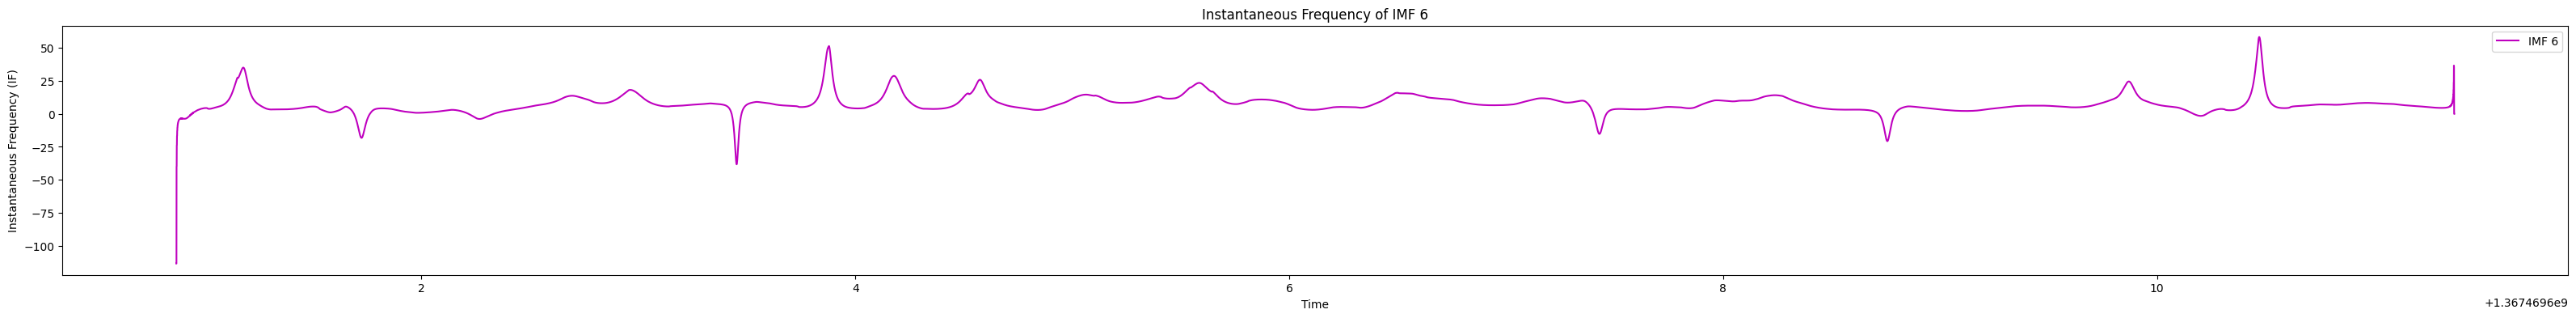

In [186]:
for i in range(n):
    # Run the function to obtain IA for the specific IMF component
#     freq_edges, freq_centres = emd.spectra.define_hist_bins(0, 500, 500, 'linear')
    IP, IF, IA, imf_n, f, hht = frequencytransform(i, 7200, method)
#     f, spec_unweighted = emd.spectra.hilberthuang(IF, np.ones_like(IA), freq_edges, sum_imfs=False)
#     f, spec_weighted = emd.spectra.hilberthuang(IF,IA, freq_edges, sum_imfs=False)
    
    plt.figure(figsize=(40, 4))
    plt.plot(t,IF, label=f'IMF {i+1}')
#     plt.plot(f,spec_weighted , label=f'IMF {i+1}')
    
    # Add labels, title, and legend
    plt.xlabel('Time')
    plt.ylabel('Instantaneous Frequency (IF)')
    plt.title(f'Instantaneous Frequency of IMF {i+1}')
    plt.legend()
    plt.show()

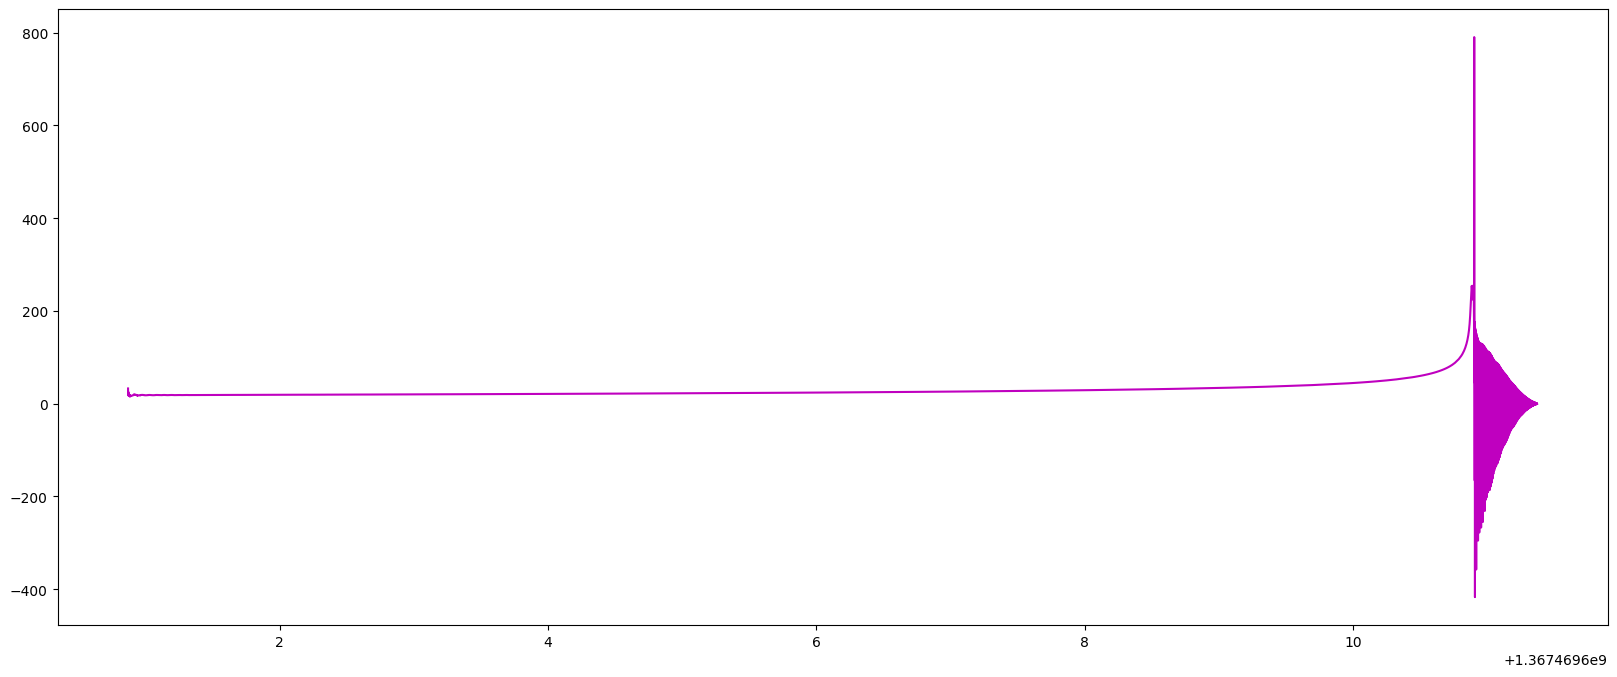

In [187]:
from scipy.signal import hilbert, chirp
analytical_signal = hilbert(O_S)
aplitude_envelope = np.abs(analytical_signal)
IP = np.unwrap(np.angle(analytical_signal))
IF = (np.diff(IP)/(2.0*np.pi) *fsamp)
t =  O_S.sample_times

plt.figure(figsize=(20,8))
plt.plot(t[1:], IF)

In [188]:
def signalconstructedhht(num_imfs_used, fs, method):
    imf = emd.sift.sift(W)
    reconstructed_signal = np.sum(imf[:, :num_imfs_used], axis=1)
    IP, IF, IA = emd.spectra.frequency_transform(reconstructed_signal, fs, method)
    freq_range = (0, 1000, 100)
    t = W.sample_times
    f, hht = emd.spectra.hilberthuang(IF, IA, freq_range, sum_time= False)
    return IP, IF, IA, reconstructed_signal,f,hht,        

In [189]:
method = 'nht'
num_imfs_used = 4 
IP, IF, IA, reconstructed_signal, f, hht = signalconstructedhht(num_imfs_used, fsamp, method)
print(reconstructed_signal)

[-0.27698838  0.6153436   1.390972   ...  0.79268868  1.07128002
  1.03333041]


<Axes: title={'center': 'Hilbert-Huang Transform'}, xlabel='Time', ylabel='Frequency'>

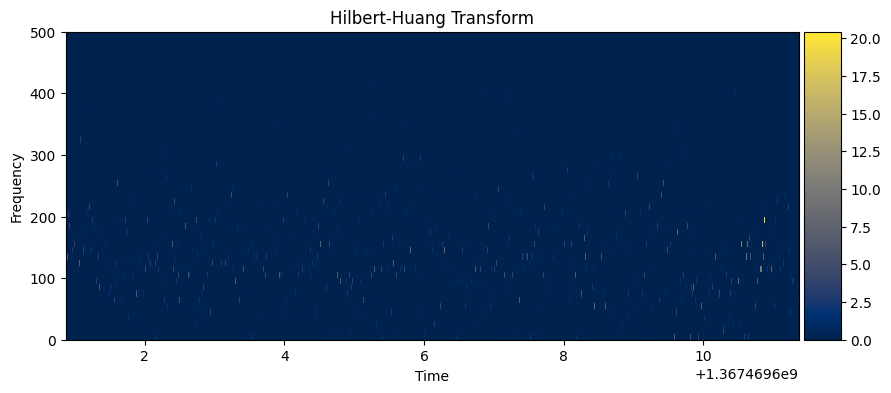

In [190]:
fig = plt.figure(figsize=(10, 4))
emd.plotting.plot_hilberthuang(hht, t, f, freq_lims=(0, 500), fig=fig, cmap= 'cividis')

### Reconctruction error

In [191]:
import numpy as np

def reconstruction_error(original_signal, imfs, num_imfs_used):
    reconstructed_signal = np.sum(imfs[:, :num_imfs_used], axis=1)
    mse = np.mean((original_signal - reconstructed_signal) ** 2)
    return mse

num_imfs_used = 5
error = reconstruction_error(W, imf, num_imfs_used)
print(f"Reconstruction error using {num_imfs_used} IMFs: {error}")


Reconstruction error using 5 IMFs: 0.002178792731831817


In [192]:
imf_ = emd.sift.sift(W)

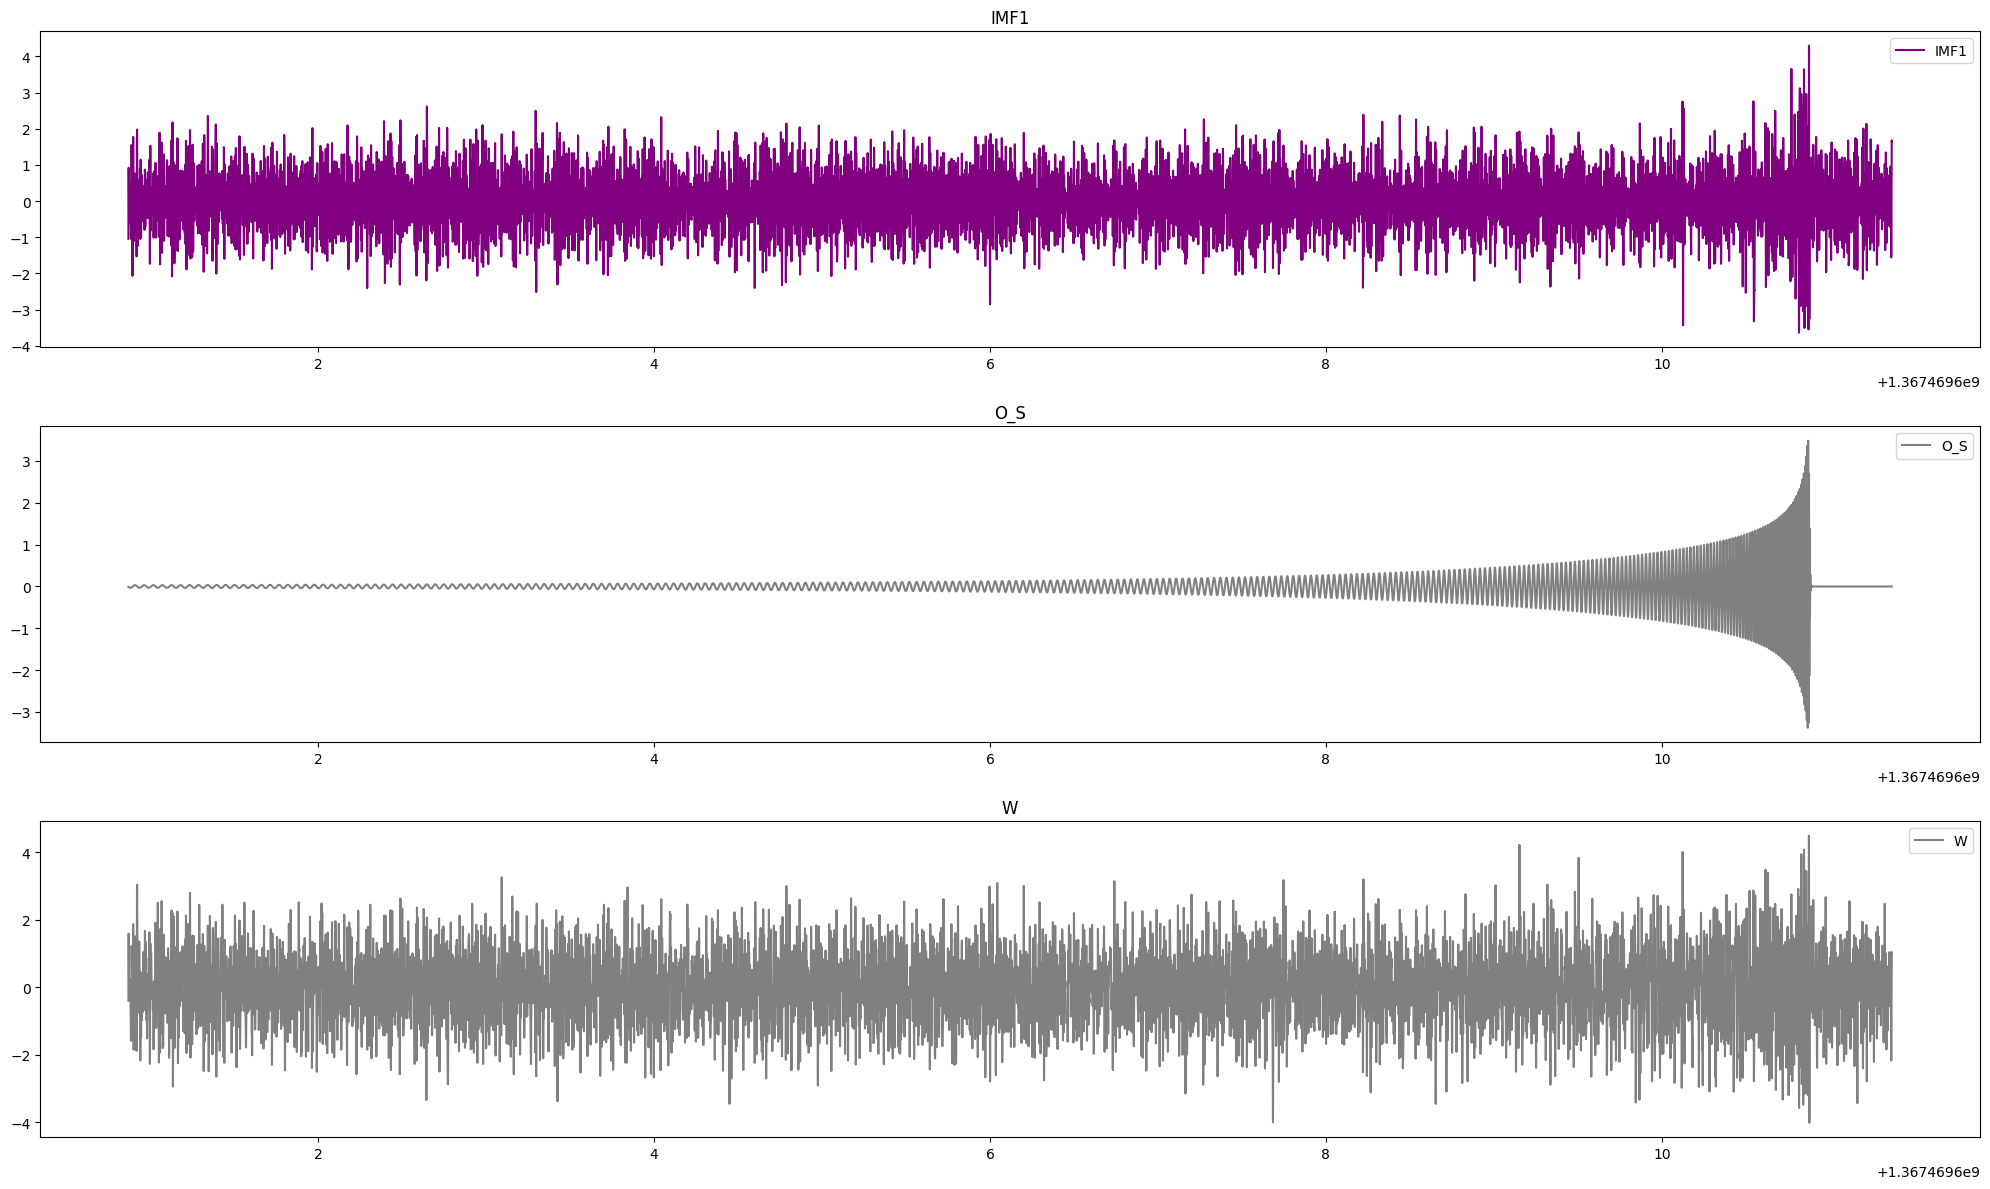

In [193]:
imf1 = imf[:, 0]

# Set up the figure
plt.figure(figsize=(20, 12))

# Plot IMF1
plt.subplot(3, 1, 1)  # Adjust to a 3-row layout
plt.plot(t, imf1, color='purple', label='IMF1')
plt.title('IMF1')
plt.legend()

# Plot O_S
plt.subplot(3, 1, 2)
plt.plot(O_S.sample_times, O_S, color='gray', label='O_S')
plt.title('O_S')
plt.legend()

# Plot W
plt.subplot(3, 1, 3)
plt.plot(W.sample_times, W, color='gray', label='W')
plt.title('W')
plt.legend()

# Show the plots
plt.tight_layout()
plt.show()


In [194]:
print(tTrigger)

1367469610.8703537


## Merger time calculate by noisy data

In [195]:
from scipy.signal import find_peaks
peaks, _ = find_peaks(W)

# If there are any peaks, find the one with the maximum value
if len(peaks) > 0:
    max_peak_index = peaks[np.argmax(W[peaks])]  # Index of the maximum peak
    time_at_max_peak2 = t[max_peak_index]  # Corresponding time at the max peak
    print(f"Maximum upper peak value occurs at time: {time_at_max_peak2}")
else:
    print("No peaks found in the signal.")

Maximum upper peak value occurs at time: 1367469610.8759766


## Merger time caculated by imf1

In [196]:
max_value = np.max(imf1)
max_index = np.argmax(imf1)
time_at_max = t[max_index]
print(time_at_max)

1367469610.8764648


In [197]:
time_error1 = abs(tTrigger-time_at_max_peak2)
time_error2 = abs(tTrigger - time_at_max)
print(time_error1)
print(time_error2)

0.00562286376953125
0.00611114501953125
